# Predicting Medical Insurance Costs with a Neural Network (Keras)

**Goal:** guess how much a person's medical insurance costs (`charges`) from their age, sex, BMI, number of kids, smoking, and region.

**Plan:** look at the data → clean it → build a small neural net → train it and try a few versions → test it on people it never saw → make charts → write a summary.

In [2]:
# my tools: pandas for tables, numpy for math, matplotlib for charts
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # hides TensorFlow's noisy startup logs
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# I set every seed so my numbers come out the same each run
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# makes TensorFlow math repeatable (only if this TensorFlow version has it)
if hasattr(tf.config.experimental, 'enable_op_determinism'):
    tf.config.experimental.enable_op_determinism()

start_time = time.time()  # I'm timing the whole notebook
print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.7.0


In [3]:
# I load the dataset straight from the link
df = pd.read_csv('https://raw.githubusercontent.com/TripleTen-DS/Dataset/refs/heads/main/insurance.csv')

print('Number of records:', len(df))
print('Number of columns:', df.shape[1])
df.head()

Number of records: 1338
Number of columns: 7


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
# I check what kind of data is in each column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [5]:
# Step 1c: check for missing values and duplicate rows.
# Decision: drop exact duplicates so the same person isn't counted twice.
print('Missing values per column:')
print(df.isna().sum())
print('\nDuplicate rows:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print('Rows after dropping duplicates:', len(df))

Missing values per column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows: 1
Rows after dropping duplicates: 1337


In [6]:
# Step 1d: summary stats for number columns and group counts for the text columns.
display(df.describe().round(2))
for col in ['sex', 'smoker', 'region']:
    print(df[col].value_counts(), '\n')

,age,bmi,children,charges
count,1337.00,1337.00,1337.00,1337.00
mean,39.22,30.66,1.10,13279.12
std,14.04,6.10,1.21,12110.36
min,18.00,15.96,0.00,1121.87
25%,27.00,26.29,0.00,4746.34
50%,39.00,30.40,1.00,9386.16
75%,51.00,34.70,2.00,16657.72
max,64.00,53.13,5.00,63770.43


male      675
female    662
Name: sex, dtype: int64 

no     1063
yes     274
Name: smoker, dtype: int64 

southeast    364
southwest    325
northwest    324
northeast    324
Name: region, dtype: int64 



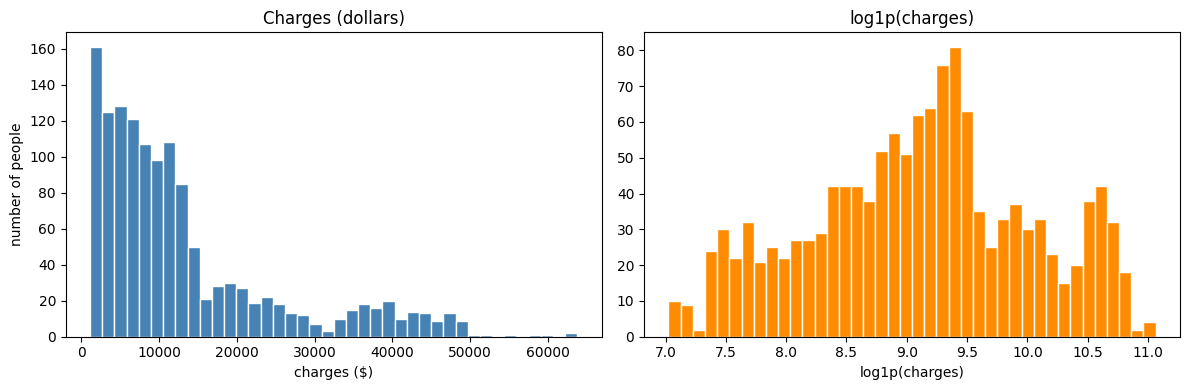

Median charges: $9386
Mean charges:   $13279
Skew (raw): 1.52   Skew (log1p): -0.09


In [7]:
# Step 1e: look at how charges are spread out.
# Decision: charges are lopsided (a few huge bills), so I compare the raw values to log1p(charges),
# which squishes big numbers and makes the shape more even and easier for the network to learn.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['charges'], bins=40, color='steelblue', edgecolor='white')
axes[0].set_title('Charges (dollars)')
axes[0].set_xlabel('charges ($)')
axes[0].set_ylabel('number of people')
axes[1].hist(np.log1p(df['charges']), bins=40, color='darkorange', edgecolor='white')
axes[1].set_title('log1p(charges)')
axes[1].set_xlabel('log1p(charges)')
plt.tight_layout()
plt.show()
print('Median charges: $%.0f' % df['charges'].median())
print('Mean charges:   $%.0f' % df['charges'].mean())
print('Skew (raw): %.2f   Skew (log1p): %.2f' % (df['charges'].skew(), np.log1p(df['charges']).skew()))

In [8]:
# Step 1f: compare smokers vs non-smokers, since smoking looks like the biggest driver of charges.
df.groupby('smoker')['charges'].agg(['count', 'mean', 'median']).round(0)

,count,mean,median
smoker,,,
no,1063,8441.0,7346.0
yes,274,32050.0,34456.0


In [9]:
# Step 2a: turn text into numbers, because a neural network only reads numbers.
# sex and smoker become 0/1; region becomes one-hot columns (drop_first avoids a redundant column).
data = df.copy()
data['sex'] = (data['sex'] == 'male').astype(int)
data['smoker'] = (data['smoker'] == 'yes').astype(int)
data = pd.get_dummies(data, columns=['region'], drop_first=True, dtype=int)
data.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,16884.92400,0,0,1
1,18,1,33.770,1,0,1725.55230,0,1,0
2,28,1,33.000,3,0,4449.46200,0,1,0
3,33,1,22.705,0,0,21984.47061,1,0,0
4,32,1,28.880,0,0,3866.85520,1,0,0


In [10]:
# Step 2b: split into train (80%) and test (20%) BEFORE scaling, so the test set stays unseen.
# Decision: stratify on smoker so both sets have the same share of smokers.
X = data.drop(columns=['charges'])
y = data['charges']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=X['smoker'])
print('Train rows:', len(X_train), ' Test rows:', len(X_test))
print('Smoker share - train: %.3f  test: %.3f' % (X_train['smoker'].mean(), X_test['smoker'].mean()))
print('Feature columns:', list(X.columns))

Train rows: 1069  Test rows: 268
Smoker share - train: 0.205  test: 0.205
Feature columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'region_northwest', 'region_southeast', 'region_southwest']


In [11]:
# Step 2c: scale age, bmi and children to the same range so no column dominates.
# Decision: fit the scaler on train only, then apply it to test, so no test info leaks into training.
# Keras wants plain float32 arrays, so I convert the tables at the end.
num_cols = ['age', 'bmi', 'children']
scaler = StandardScaler()
X_train = X_train.copy()
X_test = X_test.copy()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])
X_train_np = X_train.values.astype('float32')
X_test_np = X_test.values.astype('float32')
X_train[num_cols].describe().round(2)

,age,bmi,children
count,1069.00,1069.00,1069.00
mean,-0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-1.50,-2.44,-0.92
25%,-0.93,-0.73,-0.92
50%,-0.00,-0.05,-0.08
75%,0.85,0.65,0.77
max,1.78,3.67,3.31


In [12]:
# Step 2d: train on log1p(charges) instead of raw dollars (the target is very skewed).
# to_dollars() undoes the log with expm1 so I can report errors in real dollars.
y_train_log = np.log1p(y_train.values).astype('float32')
y_test_log = np.log1p(y_test.values).astype('float32')

def to_dollars(log_values):
    return np.expm1(np.asarray(log_values).ravel())

print('log1p(charges) range in train: %.2f to %.2f' % (y_train_log.min(), y_train_log.max()))

log1p(charges) range in train: 7.02 to 11.06


In [13]:
# Step 3: a function that builds a fresh neural network.
# Dense layers with ReLU let it learn curves; the last Dense(1) has no activation because this is regression.
# Optional Dropout randomly turns off neurons during training to fight overfitting.
# Adam is a good default optimizer, MSE is the loss for regression, MAE is easier to read.
# The seed guard keeps results repeatable on older TensorFlow versions too.
def build_model(hidden_layers=(32,), dropout=0.0, learning_rate=0.001):
    if hasattr(keras.utils, 'set_random_seed'):
        keras.utils.set_random_seed(SEED)
    else:
        tf.random.set_seed(SEED); np.random.seed(SEED); random.seed(SEED)
    model = keras.Sequential(name='insurance_nn')
    model.add(keras.Input(shape=(X_train_np.shape[1],)))
    for units in hidden_layers:
        model.add(layers.Dense(units, activation='relu'))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='mse',
        metrics=['mae'])
    return model

build_model().summary()

Model: "insurance_nn"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 32)                288       
                                                                 
 dense_1 (Dense)             (None, 1)                 33        
                                                                 
Total params: 321
Trainable params: 321
Non-trainable params: 0
_________________________________________________________________


In [14]:
# Step 4a: training helper.
# Decision: early stopping (patience 20) stops when validation loss stops improving and keeps the best weights,
# so I don't have to guess the number of epochs. 20% of the train rows are used for validation.
# dollar_mae() turns predictions back into dollars and averages the error.
def train_model(model, epochs=500, batch_size=32):
    early_stop = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=20, restore_best_weights=True)
    history = model.fit(
        X_train_np, y_train_log,
        validation_split=0.2,
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[early_stop],
        verbose=0)
    return history

def dollar_mae(model, X_part, y_dollars):
    pred = to_dollars(model.predict(X_part, verbose=0))
    return mean_absolute_error(y_dollars, pred)

In [15]:
# Step 4b: experiment with 3 architectures: a small baseline, a deeper net, and a deeper net with dropout.
# Decision: compare them on VALIDATION MAE (not test), so the test set stays a fair final check.
# These are the same last-20% rows Keras uses for validation_split.
configs = {
    'baseline (32)': dict(hidden_layers=(32,), dropout=0.0),
    'deeper (64-32)': dict(hidden_layers=(64, 32), dropout=0.0),
    'deeper + dropout (64-32, 0.2)': dict(hidden_layers=(64, 32), dropout=0.2),
}

n_val = int(len(X_train_np) * 0.2)
X_val_np, y_val_dollars = X_train_np[-n_val:], y_train.values[-n_val:]
X_fit_np, y_fit_dollars = X_train_np[:-n_val], y_train.values[:-n_val]

results, models, histories = [], {}, {}
for name, cfg in configs.items():
    t0 = time.time()
    model = build_model(**cfg)
    hist = train_model(model)
    models[name], histories[name] = model, hist
    best_epoch = int(np.argmin(hist.history['val_loss'])) + 1
    results.append({
        'config': name,
        'params': model.count_params(),
        'epochs run': len(hist.history['loss']),
        'best epoch': best_epoch,
        'train MAE ($)': round(dollar_mae(model, X_fit_np, y_fit_dollars)),
        'val MAE ($)': round(dollar_mae(model, X_val_np, y_val_dollars)),
        'seconds': round(time.time() - t0, 1),
    })

results_df = pd.DataFrame(results).sort_values('val MAE ($)').reset_index(drop=True)
results_df

,config,params,epochs run,best epoch,train MAE ($),val MAE ($),seconds
0,"deeper + dropout (64-32, 0.2)",2689,201,181,2608,3319,6.9
1,deeper (64-32),2689,133,113,2511,3494,4.5
2,baseline (32),321,227,207,2566,3585,6.7


In [16]:
# Step 4c: keep the config with the lowest validation MAE as the final model.
best_name = results_df.loc[0, 'config']
best_model = models[best_name]
best_history = histories[best_name]
print('Best config:', best_name)

Best config: deeper + dropout (64-32, 0.2)


In [17]:
# Step 5a: evaluate on the test set.
# MAE = average dollars off; R2 = share of the variation explained (1.0 is perfect).
# I also compare to a simple baseline (always guess the median) to show the model adds value.
test_loss, test_mae_log = best_model.evaluate(X_test_np, y_test_log, verbose=0)

train_pred = to_dollars(best_model.predict(X_train_np, verbose=0))
test_pred = to_dollars(best_model.predict(X_test_np, verbose=0))

train_mae = mean_absolute_error(y_train, train_pred)
test_mae = mean_absolute_error(y_test, test_pred)
train_r2 = r2_score(y_train, train_pred)
test_r2 = r2_score(y_test, test_pred)

naive_mae = mean_absolute_error(y_test, np.full(len(y_test), y_train.median()))

print('Test loss (MSE on log scale): %.4f' % test_loss)
print('Test MAE on log scale:        %.4f' % test_mae_log)
print()
print('Train MAE: $%.0f   Train R2: %.3f' % (train_mae, train_r2))
print('Test MAE:  $%.0f   Test R2:  %.3f' % (test_mae, test_r2))
print('Guess-the-median MAE on test: $%.0f' % naive_mae)
print('Test median abs error: $%.0f' % np.median(np.abs(y_test.values - test_pred)))

Test loss (MSE on log scale): 0.0894
Test MAE on log scale:        0.1887

Train MAE: $2749   Train R2: 0.800
Test MAE:  $2359   Test R2:  0.863
Guess-the-median MAE on test: $8141
Test median abs error: $823


In [18]:
# Step 5b: a few example predictions (5 smokers, 5 non-smokers) to check they make sense.
sample = pd.DataFrame({
    'age': df.loc[y_test.index, 'age'],
    'smoker': df.loc[y_test.index, 'smoker'],
    'bmi': df.loc[y_test.index, 'bmi'],
    'actual ($)': y_test.values.round(0),
    'predicted ($)': test_pred.round(0),
})
sample['error ($)'] = (sample['predicted ($)'] - sample['actual ($)']).round(0)
sample.groupby('smoker', group_keys=False).sample(5, random_state=SEED)

,age,smoker,bmi,actual ($),predicted ($),error ($)
1080,32,no,27.835,4454.0,4817.0,363.0
1124,63,no,25.080,14255.0,14187.0,-68.0
813,36,no,34.430,5584.0,5667.0,83.0
496,31,no,23.600,4932.0,4845.0,-87.0
1211,18,no,21.470,1702.0,2714.0,1012.0
1206,36,yes,33.400,38415.0,34660.0,-3755.0
1084,39,yes,18.300,19023.0,20016.0,993.0
444,56,yes,26.695,26109.0,30844.0,4735.0
86,57,yes,31.160,43579.0,36675.0,-6904.0
322,34,yes,30.800,35492.0,30693.0,-4799.0


In [19]:
# Step 5c: diagnose fit. A big train/test gap means overfitting; high error on both means underfitting.
# I also split the test error by smoker to see where the big misses are.
gap = (test_mae - train_mae) / train_mae * 100
print('Test MAE is %.1f%% %s than train MAE' % (abs(gap), 'higher' if gap > 0 else 'lower'))
if gap > 25:
    print('-> big gap: looks like overfitting')
elif test_mae > 0.5 * naive_mae:
    print('-> errors are high on both: looks like underfitting')
else:
    print('-> train and test are close: no strong overfitting')

err = pd.DataFrame({'smoker': df.loc[y_test.index, 'smoker'],
                    'abs_error': np.abs(y_test.values - test_pred)})
err.groupby('smoker')['abs_error'].agg(['count', 'mean', 'median']).round(0)

Test MAE is 14.2% lower than train MAE
-> train and test are close: no strong overfitting


,count,mean,median
smoker,,,
no,213,1328.0,487.0
yes,55,6352.0,6369.0


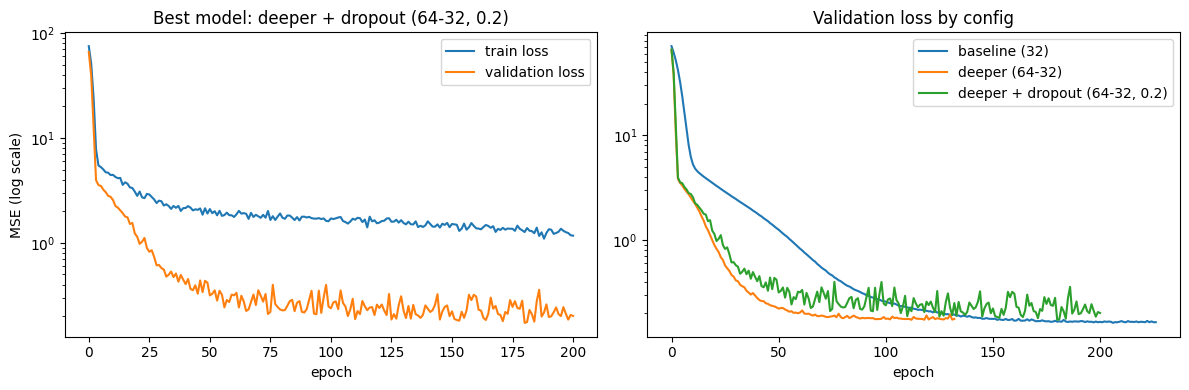

In [20]:
# Step 6a: training vs validation loss curves.
# If validation loss climbed back up while training loss kept dropping, that would mean overfitting.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(best_history.history['loss'], label='train loss')
axes[0].plot(best_history.history['val_loss'], label='validation loss')
axes[0].set_title('Best model: ' + best_name)
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('MSE (log scale)')
axes[0].set_yscale('log')
axes[0].legend()
for name, hist in histories.items():
    axes[1].plot(hist.history['val_loss'], label=name)
axes[1].set_title('Validation loss by config')
axes[1].set_xlabel('epoch')
axes[1].set_yscale('log')
axes[1].legend()
plt.tight_layout()
plt.show()

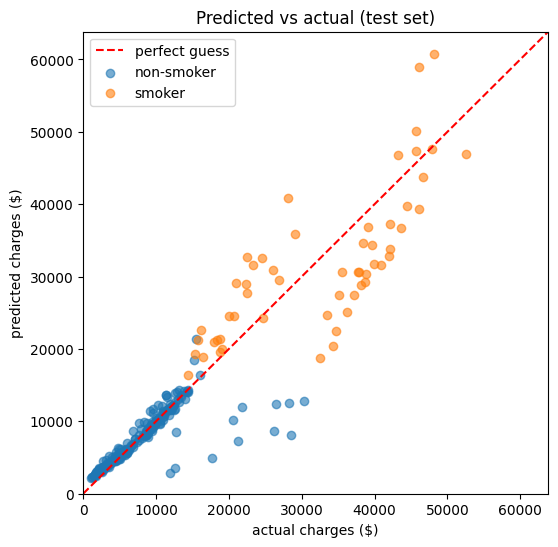

In [21]:
# Step 6b: predicted vs actual on the test set. Dots on the red dashed line are perfect guesses.
smoker_mask = df.loc[y_test.index, 'smoker'].values == 'yes'
plt.figure(figsize=(6, 6))
plt.scatter(y_test[~smoker_mask], test_pred[~smoker_mask], alpha=0.6, label='non-smoker')
plt.scatter(y_test[smoker_mask], test_pred[smoker_mask], alpha=0.6, label='smoker')
lim = [0, max(y_test.max(), test_pred.max()) * 1.05]
plt.plot(lim, lim, 'r--', label='perfect guess')
plt.xlim(lim); plt.ylim(lim)
plt.xlabel('actual charges ($)')
plt.ylabel('predicted charges ($)')
plt.title('Predicted vs actual (test set)')
plt.legend()
plt.show()

In [22]:
# Step 6c: final model architecture and the number of learned parameters.
best_model.summary()
print('Total parameters:', best_model.count_params())

Model: "insurance_nn"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_7 (Dense)             (None, 64)                576       
                                                                 
 dropout (Dropout)           (None, 64)                0         
                                                                 
 dense_8 (Dense)             (None, 32)                2080      
                                                                 
 dropout_1 (Dropout)         (None, 32)                0         
                                                                 
 dense_9 (Dense)             (None, 1)                 33        
                                                                 
Total params: 2,689
Trainable params: 2,689
Non-trainable params: 0
_________________________________________________________________
Total parameters: 2689


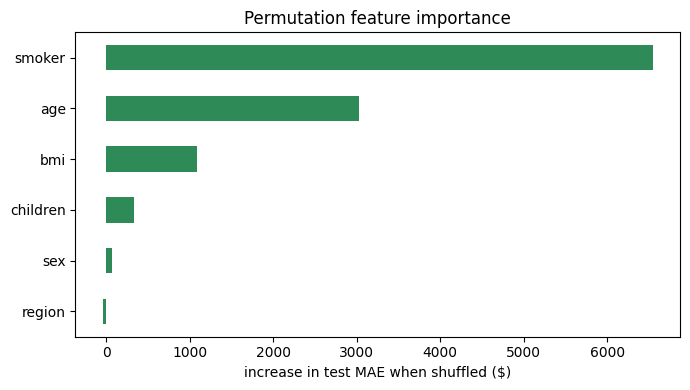

smoker      6542.0
age         3029.0
bmi         1092.0
children     334.0
sex           67.0
region       -41.0
dtype: float64

In [23]:
# Step 6d: permutation importance. I shuffle one feature at a time and measure how much test MAE rises.
# A bigger rise means the model relies on that feature more. Region's one-hot columns are shuffled together.
# I average 5 shuffles so the result is less random.
feature_groups = {c: [c] for c in ['age', 'sex', 'bmi', 'children', 'smoker']}
feature_groups['region'] = [c for c in X_test.columns if c.startswith('region_')]

rng = np.random.default_rng(SEED)
importance = {}
for feat, cols in feature_groups.items():
    idx = [list(X_test.columns).index(c) for c in cols]
    increases = []
    for _ in range(5):
        X_shuffled = X_test_np.copy()
        X_shuffled[:, idx] = X_shuffled[rng.permutation(len(X_shuffled))][:, idx]
        shuffled_mae = mean_absolute_error(y_test, to_dollars(best_model.predict(X_shuffled, verbose=0)))
        increases.append(shuffled_mae - test_mae)
    importance[feat] = np.mean(increases)

importance = pd.Series(importance).sort_values()
importance.plot(kind='barh', color='seagreen', figsize=(7, 4))
plt.xlabel('increase in test MAE when shuffled ($)')
plt.title('Permutation feature importance')
plt.tight_layout()
plt.show()

importance.sort_values(ascending=False).round(0)

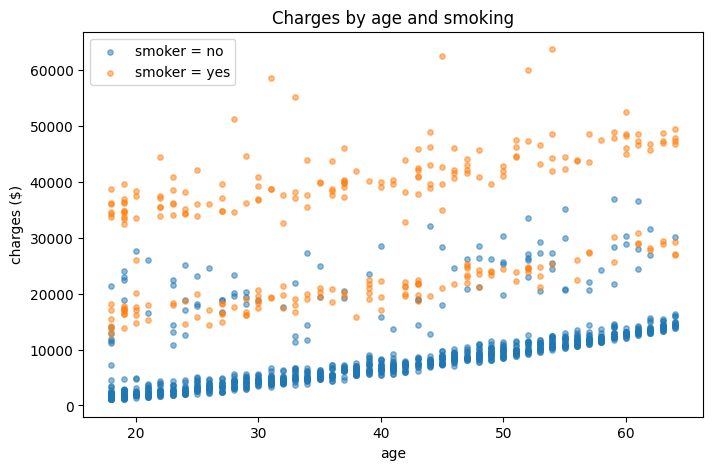

Total notebook runtime: 1513.7 seconds


In [24]:
# Step 6e: raw charges by age, colored by smoker, to show the pattern the model learned.
plt.figure(figsize=(8, 5))
for status, color in [('no', 'tab:blue'), ('yes', 'tab:orange')]:
    part = df[df['smoker'] == status]
    plt.scatter(part['age'], part['charges'], alpha=0.5, s=15, color=color, label='smoker = ' + status)
plt.xlabel('age')
plt.ylabel('charges ($)')
plt.title('Charges by age and smoking')
plt.legend()
plt.show()

print('Total notebook runtime: %.1f seconds' % (time.time() - start_time))

## Summary

### Process
- **Data:** 1,338 rows and 7 columns, with no missing values. I dropped 1 duplicate row, leaving 1,337 people.
- **Target:** `charges` is lopsided because a few people have very large bills, so I trained on `log1p(charges)` and turned the predictions back into dollars with `expm1`.
- **Preprocessing:** `sex` and `smoker` became 0/1 and `region` became one-hot columns, for 8 input features. I split the data 80/20 (1,069 train / 268 test), stratified on smoker, and scaled `age`, `bmi`, and `children` with a StandardScaler fit on the train set only.
- **Model:** a Keras Sequential network with Dense ReLU hidden layers and 1 output. It was trained with Adam, MSE loss, and MAE as the metric, with batch size 32, up to 500 epochs, a 20% validation split, and early stopping (patience 20).

### Experiments (picked by validation MAE)
| config | params | best epoch | train MAE | val MAE |
|---|---|---|---|---|
| deeper + dropout (64-32, 0.2) | 2,689 | 181 | `$2,608` | **`$3,319`** |
| deeper (64-32) | 2,689 | 113 | `$2,511` | `$3,494` |
| baseline (32) | 321 | 207 | `$2,566` | `$3,585` |

### Results
- **Best model:** 64 → 32 → 1 with 0.2 dropout (2,689 parameters).
- **Test set:** MAE **`$2,359`**, R² **0.863**, median error `$823`.
- **Train set:** MAE `$2,749`, R² 0.800.
- **Baseline:** always guessing the median bill gives a test MAE of `$8,141`, so the model cuts the error by about 71%.
- **Fit:** test MAE is 14% *lower* than train MAE, and the validation loss flattens instead of rising, so the model is **not overfitting**. It isn't underfitting either, since it beats the baseline by a wide margin.
- **Where it struggles:** smokers have a mean error of `$6,352`, versus `$1,328` for non-smokers. Smokers' bills vary much more, and the data doesn't explain all of that variation.

### Insights
- **Most important features** (how much the test MAE rises when the column is shuffled): **smoker** (+`$6,542`), then **age** (+`$3,029`), then **bmi** (+`$1,092`). Children (+`$334`), sex (+`$67`), and region (-`$41`) barely matter.
- Dropout helped a little here, and the small baseline was close behind, so this data doesn't need a big network.
- **Next steps:** add a smoker × BMI feature, try a Huber loss for the expensive smokers, use k-fold cross-validation, and compare against a gradient-boosting model.

### Decisions I made (and why)
- **Dropped the duplicate row** so one person isn't counted twice.
- **Trained on log1p(charges)** because a few huge bills made the data lopsided, and the log version is easier for the network to learn.
- **Split before scaling, and fit the scaler on train only,** so no information from the test set leaks into training.
- **Stratified the split on smoker** so both sets have the same share of smokers, since smoking drives the bills the most.
- **Used early stopping** so the model stops training when validation loss stops improving, instead of me guessing the number of epochs.
- **Picked the best model by validation MAE, not test MAE,** so the test set stays a fair final check.

### Reflection
- The biggest gains came from preparing the data (the log target, scaling, and encoding), not from making the network bigger. The small baseline model was close to the best one.
- I expected dropout to hurt, since the model wasn't overfitting, but it helped a little. Trying it was better than assuming.
- The hardest part was the smokers. Their bills vary a lot, and the 6 columns we have can't fully explain why, so the model misses them by about `$6,350` on average versus about `$1,330` for non-smokers.
- I had to adjust my setup code for the platform's older TensorFlow (2.7) because one setting didn't exist in that version. That taught me to check library versions before assuming code will run everywhere.
- If I did this again, I'd try a smoker × BMI feature and k-fold cross-validation, and compare against a simpler model like gradient boosting.
